In [148]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)

Implementation of SARSA algorithm in a gridworld environement

In [ ]:
class GridWorld:
    def __init__(self, width=5, height=5):
        self.width = width
        self.height = height

        self.destination = (width-1, height-1)

        self.init_state_values()
        self.reset()

    def init_state_values(self):
        self.state_values = {}
        for y in range(self.height):
            for x in range(self.width):
                self.state_values[(x,y)] = {}

                if x > 0:
                    self.state_values[(x, y)][3] = 0 # !!! TRY ALSO WITH DIFFERENT INITIALIZATIONS
                if y > 0:
                    self.state_values[(x, y)][0] = 0
                if x < self.width-1:
                    self.state_values[(x, y)][1] = 0
                if y < self.height-1:
                    self.state_values[(x, y)][2] = 0

        self.state_values[(self.height-1, self.width-1)] = {}

    def reset(self):
        self.agent_position = (0,0)

    def isTerminated(self):
        return self.agent_position == self.destination

    def getState(self):
        return self.agent_position

    def getActions(self):
        # 0=up, 1=right, 2=down, 3=left
        possible_actions = []

        x, y = self.agent_position
        
        if x > 0:
            possible_actions.append(3)
        if y > 0:
            possible_actions.append(0)
        if x < self.width-1:
            possible_actions.append(1)
        if y < self.height-1:
            possible_actions.append(2)
        
        return possible_actions

    def doAction(self, action):
        x, y = self.agent_position
        if action == 0:
            y -= 1
        elif action == 1:
            x += 1
        elif action == 2:
            y += 1
        else:
            x -= 1
        self.agent_position = (x, y)

    def getReward(self):
        return -1
    
    def getPolicy(self, x, y):
        return self.state_values[(x,y)]

    def getStateValue(self, x, y, action):
        if x == self.width-1 and y == self.height-1:
            return 0 # Terminal state value
        
        return self.state_values[(x,y)][action]
    
    def setStateValue(self, x, y, action, newValue):
        self.state_values[(x,y)][action] = newValue
    
    def getAgentPosition(self):
        return self.agent_position

In [ ]:
def get_epsilon_greedy_action(env, eps, x, y):
    actions = env.getActions()

    if random.random() < eps:
        return random.choice(actions)
    else:
        q_values = [env.getStateValue(x, y, a) for a in actions]
        max_q = max(q_values)
        
        best_actions = [a for a, q in zip(actions, q_values) if q == max_q]
        return random.choice(best_actions)

def train(env, eps, alpha, gamma):
    nSteps = 0
    
    x, y = env.getAgentPosition()
    action = get_epsilon_greedy_action(env, eps, x, y)

    while not env.isTerminated():
        xPre, yPre = x, y
        stateValuePre = env.getStateValue(xPre, yPre, action)

        # Take action
        env.doAction(action)
        reward = env.getReward()
        
        x, y = env.getAgentPosition()
        
        if env.isTerminated():
            target = reward # + gamma * 0
            newStateValue = stateValuePre + alpha * (target - stateValuePre)
            env.setStateValue(xPre, yPre, action, newStateValue)
            break

        # Next action A'
        actionNext = get_epsilon_greedy_action(env, eps, x, y)
        stateValueNext = env.getStateValue(x, y, actionNext)
        
        # SARSA Update: Q(S,A) <-- Q(S,A) + alpha * [R + gamma * Q(S', A') - Q(S,A)]
        newStateValue = stateValuePre + alpha * (reward + gamma*stateValueNext - stateValuePre)
        env.setStateValue(xPre, yPre, action, newStateValue)

        action = actionNext
        nSteps += 1

    return nSteps

In [151]:
env = GridWorld(10, 10)

eps = 0.9
alpha = 0.5
gamma = 0.99

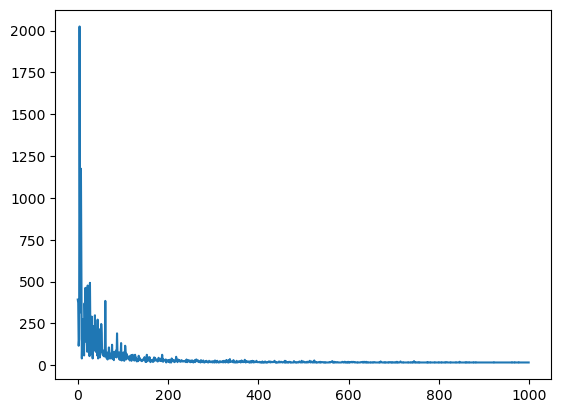

[17, 17, 17, 17, 17, 17, 17, 19, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17]
17.0
Eps: 0.006653968578831948


In [ ]:
stepsOverTime = []
nEphocs = 1000

eps = 1.0 
min_eps = 0.00
decay = 0.995

env.init_state_values() 

for _ in range(nEphocs):
    env.reset()
    lastSteps = train(env, eps, alpha, gamma)
    stepsOverTime.append(lastSteps)
    
    # Decay epsilon
    eps = max(min_eps, eps * decay)

plt.plot(list(range(nEphocs)), stepsOverTime)
plt.show()

print(stepsOverTime[-30:])
lastNs = int(nEphocs*0.01)
print(sum(stepsOverTime[-lastNs:])/lastNs)
print(f"Eps: {eps}")

In [155]:
# 0=up, 1=right, 2=down, 3=left
action_symbols = {0: '↑', 1: '→', 2: '↓', 3: '←'}

print("Policy Grid:")
print("-" * (env.width * 3 + 1))

for y in range(env.height):
    row_str = "|"
    for x in range(env.width):
        if (x, y) == env.destination:
            row_str += " G|"
            continue
        
        possible_actions = []
        if x > 0: possible_actions.append(3)
        if y > 0: possible_actions.append(0)
        if x < env.width-1: possible_actions.append(1)
        if y < env.height-1: possible_actions.append(2)
        
        best_action = -1
        max_val = -float('inf')
        
        for action in possible_actions:
            val = env.getStateValue(x, y, action)
            if val > max_val:
                max_val = val
                best_action = action
        
        symbol = action_symbols.get(best_action, ' ')
        row_str += f" {symbol}|"
    print(row_str)
    print("-" * (env.width * 3 + 1))

Policy Grid:
-------------------------------
| →| →| ↓| ↓| ↓| →| ↓| ↓| →| ↓|
-------------------------------
| ↓| →| ↓| ↓| ↓| ↓| →| ↓| ↓| ↑|
-------------------------------
| ↓| →| →| ↓| ↓| →| ↓| ↓| ↓| ↓|
-------------------------------
| ↓| ←| →| ↓| ↓| ↓| ↓| ↓| ↓| ↓|
-------------------------------
| →| →| ↓| →| →| ↓| ↓| ↓| ↓| ↓|
-------------------------------
| →| →| ↓| →| →| ↓| ↓| ↓| ↓| ↓|
-------------------------------
| ↓| ↑| →| →| →| →| →| →| ↓| ↓|
-------------------------------
| ↓| ↓| ↓| ↓| ↓| →| →| →| ↓| ↓|
-------------------------------
| →| →| →| →| →| →| →| ↓| →| ↓|
-------------------------------
| →| →| →| ↑| ↑| →| →| →| →| G|
-------------------------------
